# Machine Learning - Practical 6

Names: {YOUR NAMES}

In [1]:
import pickle
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.stats import multivariate_normal
from scipy.special import logsumexp

sns.set(context='talk',style='white',palette='colorblind')

## Task 0: Load data

To explore different clustering algorithms, we generated a toy dataset that consists of 5000 data points from a two dimensional mixture of Gaussian model with seven clusters.
Plot the data points with different colors for each cluster and indicated the cluster means.

In [2]:
# load data
with open('data/data_gmms.pkl', 'rb') as f:
    dataset = pickle.load(f)

In [3]:
def plot_clustering(data, cluster_ids, means, title):
    '''
    Plots the (2D) data as scatter plot, with different colors and an extra symbol for the mean per cluster.
    inputs:
        data        -- (n_samples, n_features)-shaped array of data
        cluster_ids -- (n_samples,)-shaped array of integers that hold the cluster assignment for each data point
        means       -- (n_clusters, n_features)-shaped array of mean vectors
        title       -- string that is added as title

    '''

    # ---------------- INSERT CODE ----------------------

    plt.figure(figsize=(10,6))
    
    plt.scatter(data[:, 0], data[:, 1], c=cluster_ids)
    plt.scatter(means[:, 0], means[:, 1], c='blue', marker='x')
    
    plt.title(title)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.axis('equal')

    plt.show()
    
    # ---------------- END CODE -------------------------

In [4]:
toy_data = dataset['data']
toy_cluster_ids_true = dataset['labels']
toy_means = dataset['means']

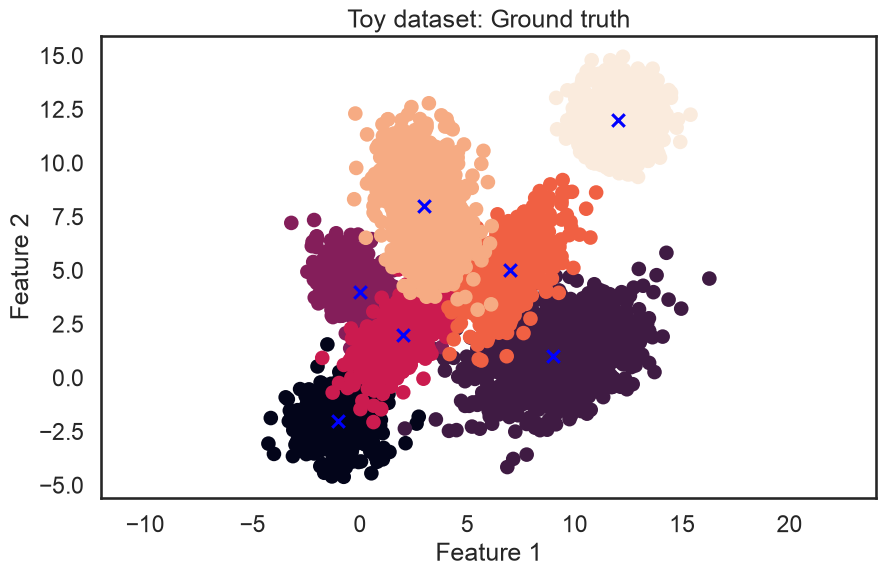

In [5]:
plot_clustering(toy_data, toy_cluster_ids_true, toy_means, 'Toy dataset: Ground truth')

## Task 1: Cluster the data using k-Means

First, we will implement k-Means as an example of a simple clustering algorithm and see how it performs on the dataset. 

Use the function KMeans provided by sklearn to perform K-Means with different numbers of clusters, for instance 3, 5, 7, 10 and 20.

In [6]:
def run_KMeans(data, n_clusters):
    '''Function that performs K-means clustering for a given number of clusters.
        input:
            data: (n_samples, n_features)-shaped array of data
            number of clusters: int, number of clusters
        output:
            kmeans_result: (n_samples,)-shaped array of integers that hold the cluster assignment for each data point
    '''

    # ---------------- INSERT CODE ----------------------

    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(data)
    
    kmeans_result = kmeans.labels_
    
    # ---------------- END CODE -------------------------
    
    return kmeans_result

In [7]:
# run kmeans with different numbers of clusters

# ---------------- INSERT CODE ----------------------

arr = np.array([3,5,7,10,20])
results = {}

for i in arr:
    res = run_KMeans(toy_data, i)
    results[i] = res

# ---------------- END CODE -------------------------

Plot your results as cluster labels using the "plot_clustering" function and compare it to the original cluster labels. Describe your results.

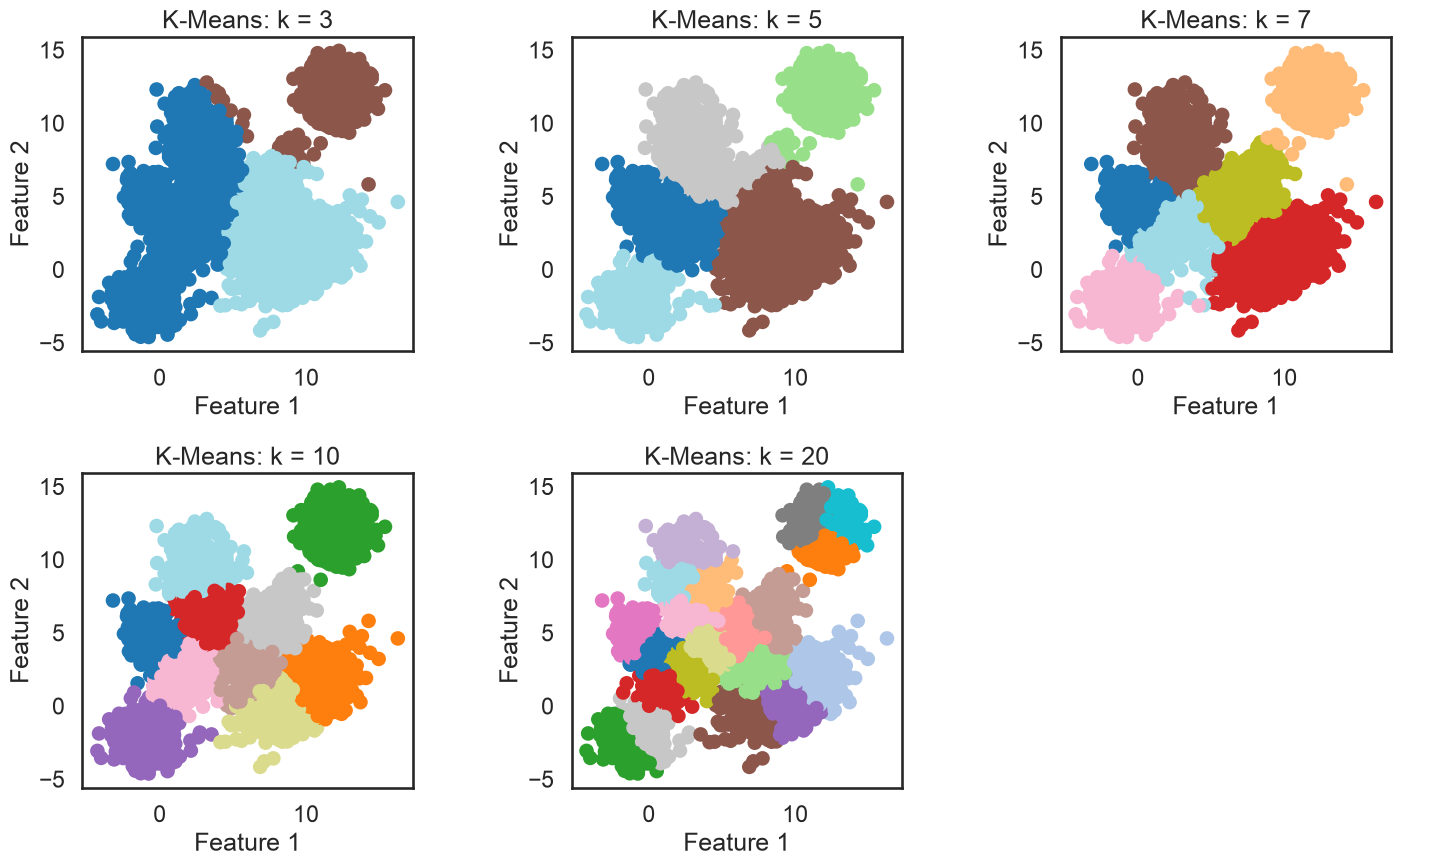

In [8]:
# plot results
# ---------------- INSERT CODE ----------------------

def plot_kmeans_results(data, results):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    for ax, (k, labels) in zip(axes.flat, results.items()):
        ax.scatter(data[:, 0], data[:, 1], c=labels, cmap='tab20')
        ax.set_title(f'K-Means: k = {k}')
        ax.set_xlabel('Feature 1')
        ax.set_ylabel('Feature 2')
        ax.set_aspect('equal')

    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()


plot_kmeans_results(toy_data, results)

# ---------------- END CODE -------------------------

**A:**

The results show that the choice of the number of clusters has a significant impact on the clustering.

For k = 3 and k = 5, several clusters from the ground truth are merged because the number of clusters is too small.

For k = 7, the number of clusters matches the ground truth. However, k-Means does not perfectly recover the original cluster assignments, especially in regions where clusters overlap.

For k = 10 and k = 20, several original clusters are divided into smaller clusters.

Overall, k-Means performs reasonably well for clearly separated clusters but struggles with overlapping and elongated clusters because it assigns each data point to the nearest cluster center.

##  Task 2: Clustering using Gaussian Mixture Models

Next, we will implement clustering with Gaussian Mixture models as discussed in the Bishop in Chapter 9.2.2 pg. 435-439.

Implement the EM algorithm to fit a Gaussian mixture model on the data. Sort the data points by inferring their class labels from your mixture model (by using maximum a-posteriori classification). Fix the seed of the random number generator to ensure deterministic and reproducible behavior. 

For this task, it is important to think about a good way to initialize the means, covariances and mixing coefficients. Also, during optimization, covariance matrices can become singular. To prevent this, you can add a small constant (like $10^{-5}$) to the diagonal.

In order to speed up the computation, define a convergence criterion that stops the algorithm after convergence.

In [9]:
def gmm(data, n_clusters, verbose=True, max_iter=1000, convergence_threshold=1e-4):
    '''Function that fits a mixture of gaussians to data.

        inputs:
            data          -- (n_samples, n_features)-shaped array of data points
            n_clusters    -- int, number of clusters / mixture components
            verbose       -- bool, if True, print current likelihood after each EM iteration
            max_iter      -- maximum number of EM iterations
            convergence_threshold  -- stop algorithm if change in log-lieklihood is below the treshold

        outputs:
            cluster_ids -- (n_samples,)-shaped array of integers that hold the cluster assignment for each data point
            means       -- (n_clusters, n_features)-shaped array of fit mean vectors
            covs        -- (n_features, n_features, n_clusters)-shaped array of fit covariance matrices
            priors      -- (n_clusters)-shaped arrays of fit priors / mixing coefficients
        '''

    # ---------------- INSERT CODE ----------------------

    ### INITIALIZATION ###

    n_samples, n_features = data.shape

    #rng = np.random.default_rng(42)

    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(data)
    
    means = kmeans.cluster_centers_.copy()

    covs = np.repeat(
        np.cov(data, rowvar=False)[:, :, None],
        n_clusters,
        axis=2
    )
    
    priors = np.ones(n_clusters) / n_clusters

    previous_ll = None

    ### ALTERNATE BETWEEN E & M STEP ###

    for iteration in range(max_iter):

        ### E-STEP ###

        log_probs = np.zeros((n_samples, n_clusters))

        for k in range(n_clusters):
            log_probs[:, k] = (
                np.log(priors[k])
                + multivariate_normal.logpdf(
                    data, mean=means[k], cov=covs[:, :, k]
                )
            )

        responsibilities = np.exp(
            log_probs - logsumexp(log_probs, axis=1, keepdims=True)
        )

        ### M-STEP ###

        N_k = responsibilities.sum(axis=0)
        N_k = np.maximum(N_k, 1e-10)

        priors = N_k / N_k.sum()

        means = (responsibilities.T @ data) / N_k[:, None]

        for k in range(n_clusters):
            diff = data - means[k]

            covs[:, :, k] = (
                (responsibilities[:, k, None] * diff).T @ diff
            ) / N_k[k]

            covs[:, :, k] += 1e-5 * np.eye(n_features)
        

        ### CHECK FOR CONVERGENCE/ PRINT LOG_LIKELIHOOD if VERBOSE ###

        for k in range(n_clusters):
            log_probs[:, k] = (
                np.log(priors[k])
                + multivariate_normal.logpdf(
                    data, mean=means[k], cov=covs[:, :, k]
                )
            )
        
        current_ll = logsumexp(log_probs, axis=1).sum()

        if verbose and (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Log-Likelihood = {current_ll:.4f}")

        if previous_ll is not None:
            if abs(current_ll - previous_ll) < convergence_threshold:
                break

        previous_ll = current_ll
        
    ### ASSIGN CLUSTER LABELS ###

    cluster_ids = np.argmax(log_probs, axis=1)
    
    # ---------------- END CODE -------------------------

    return (cluster_ids, means, covs, priors)

Explore the results of GMM using different numbers of clusters and initialization strategies.

In [10]:
# fit GMM
gmm_ids, means, covs, priors = gmm(toy_data,n_clusters=7,verbose=True)

Iteration 10: Log-Likelihood = -25734.3381
Iteration 20: Log-Likelihood = -25560.9355
Iteration 30: Log-Likelihood = -24971.7947
Iteration 40: Log-Likelihood = -24900.2180
Iteration 50: Log-Likelihood = -24866.3698
Iteration 60: Log-Likelihood = -24857.7343
Iteration 70: Log-Likelihood = -24856.4565
Iteration 80: Log-Likelihood = -24856.1909
Iteration 90: Log-Likelihood = -24856.1331
Iteration 100: Log-Likelihood = -24856.1211
Iteration 110: Log-Likelihood = -24856.1187


Plot the data points from the toy dataset and indicate in color the cluster each point was assigned to by your model. How does the assignment compare to ground truth? How does it compare to the k-Means solution? Plot ground truth, k-Means and GMM cluster assignment side-by-side to compare them.

If you run the algorithm multiple times, you will notice that some solutions provide suboptimal clustering solutions - depending on your initialization strategy.

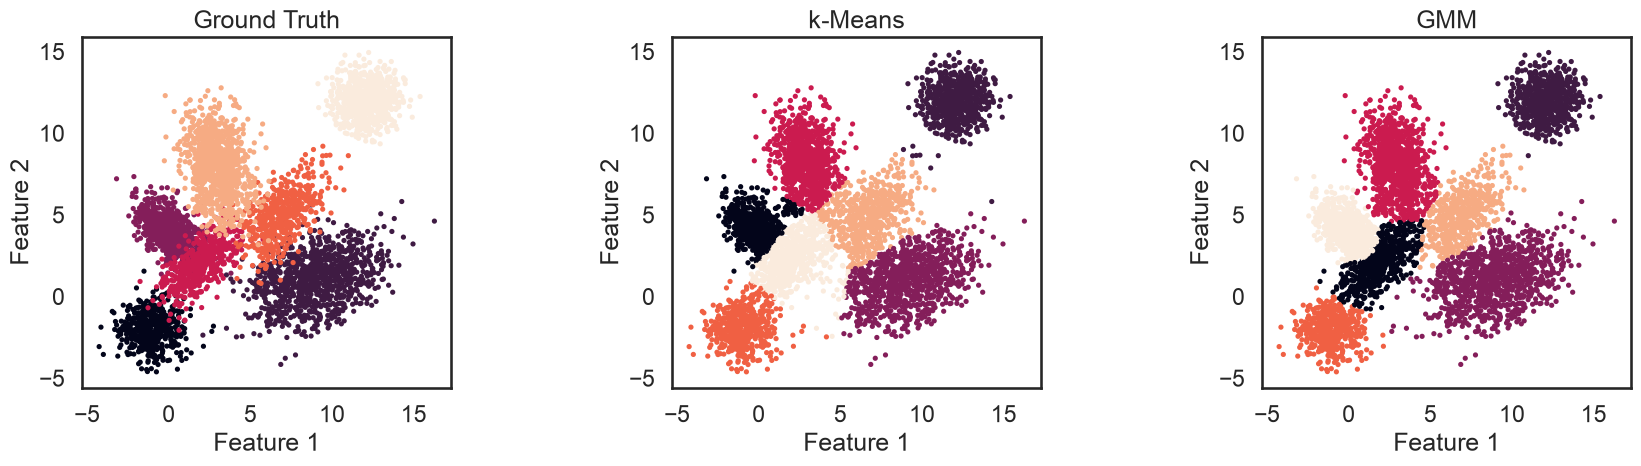

In [11]:
kmeans = KMeans(n_clusters=7, random_state=42)
kmeans_ids = kmeans.fit_predict(toy_data)

# plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

clusterings = {
    "Ground Truth": toy_cluster_ids_true,
    "k-Means": kmeans_ids,
    "GMM": gmm_ids
}

for ax, (title, labels) in zip(axes, clusterings.items()):
    ax.scatter(
        toy_data[:, 0],
        toy_data[:, 1],
        c=labels,
        s=5
    )
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

**A:**

The GMM provides a better clustering result than k-Means, particularly for elongated and overlapping clusters. While k-Means assigns points based on their Euclidean distance to the cluster centers, the GMM also considers the covariance matrices of the Gaussian components. This allows it to model clusters with different shapes and orientations.

Compared to the ground truth, the GMM captures the elongated cluster in the central region more accurately. However, some points are still assigned differently, especially in overlapping regions.

The results also depend on the initialization, since the EM algorithm can converge to local optima.